<a href="https://colab.research.google.com/github/Nerolero/AVD-20262-pratica-streamlit/blob/main/notebooks/eda-com-downloads.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


1. ID: unique identifier
2. N_Days: number of days between registration and the earlier of death, transplantation, or study analysis time in July 1986
3. Status: status of the patient C (censored), CL (censored due to liver tx), or D (death)
4. Drug: type of drug D-penicillamine or placebo
5. Age: age in [days]
6. Sex: M (male) or F (female)
7. Ascites: presence of ascites N (No) or Y (Yes)
8. Hepatomegaly: presence of hepatomegaly N (No) or Y (Yes)
9. Spiders: presence of spiders N (No) or Y (Yes)
10. Edema: presence of edema N (no edema and no diuretic therapy for edema), S (edema present without diuretics, or edema resolved by diuretics), or Y (edema despite diuretic therapy)
11. Bilirubin: serum bilirubin in [mg/dl]
12. Cholesterol: serum cholesterol in [mg/dl]
13. Albumin: albumin in [gm/dl]
14. Copper: urine copper in [ug/day]
15. Alk_Phos: alkaline phosphatase in [U/liter]
16. SGOT: SGOT in [U/ml]
17. Triglycerides: triglicerides in [mg/dl]
18. Platelets: platelets per cubic [ml/1000]
19. Prothrombin: prothrombin time in seconds [s]
20. Stage: histologic stage of disease (1, 2, 3, or 4)


In [2]:
# Prompt: Esse é o link do dataset, como eu devo o incorporar no colab:link

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import silhouette_score, silhouette_samples
import pandas as pd

!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

# fetch dataset
cirrhosis_patient_survival_prediction = fetch_ucirepo(id=878)

# data (as pandas dataframes)
df = cirrhosis_patient_survival_prediction.data.features
y = cirrhosis_patient_survival_prediction.data.targets

# metadata
print(cirrhosis_patient_survival_prediction.metadata)

# variable information
print(cirrhosis_patient_survival_prediction.variables)

print(df.shape)

{'uci_id': 878, 'name': 'Cirrhosis Patient Survival Prediction', 'repository_url': 'https://archive.ics.uci.edu/dataset/878/cirrhosis+patient+survival+prediction+dataset-1', 'data_url': 'https://archive.ics.uci.edu/static/public/878/data.csv', 'abstract': 'Utilize 17 clinical features for predicting survival state of patients with liver cirrhosis. The survival states include 0 = D (death), 1 = C (censored), 2 = CL (censored due to liver transplantation).', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 418, 'num_features': 17, 'feature_types': ['Real', 'Categorical'], 'demographics': ['Age', 'Sex'], 'target_col': ['Status'], 'index_col': ['ID'], 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C5R02G', 'creators': ['E. Dickson', 'P. Grambsch', 'T. Fleming', 'L. Fisher', 'A. Langworthy'], 'intro_paper': {'ID': 296, 'type'

In [3]:
df['Status'] = y['Status']

/tmp/ipykernel_3465/1315234373.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Status'] = y['Status']


In [4]:
df['Status'] = df['Status'].replace({'D': '1', 'C': '0', 'CL': '0'})
print(df.head())

              Drug    Age Sex Ascites Hepatomegaly Spiders Edema  Bilirubin  \
0  D-penicillamine  21464   F       Y            Y       Y     Y       14.5   
1  D-penicillamine  20617   F       N            Y       Y     N        1.1   
2  D-penicillamine  25594   M       N            N       N     S        1.4   
3  D-penicillamine  19994   F       N            Y       Y     S        1.8   
4          Placebo  13918   F       N            Y       Y     N        3.4   

  Cholesterol  Albumin Copper  Alk_Phos    SGOT Tryglicerides Platelets  \
0         261     2.60    156    1718.0  137.95           172       190   
1         302     4.14     54    7394.8  113.52            88       221   
2         176     3.48    210     516.0   96.10            55       151   
3         244     2.54     64    6121.8   60.63            92       183   
4         279     3.53    143     671.0  113.15            72       136   

   Prothrombin  Stage Status  
0         12.2    4.0      1  
1         10

/tmp/ipykernel_3465/902757511.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Status'] = df['Status'].replace({'D': '1', 'C': '0', 'CL': '0'})


O ideal aparentemente é utilizar o One-Hot encoder, mas para os propósitos dessa atividade eu vou mudar para simples 0 - 1

In [5]:
df_clean = df.set_axis(['Tipo Droga', 'Idade', 'Sexo', 'Ascites', 'Hepatomegalia', 'Spiders(Efeito)', 'Edema',
       'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT',
       'triglicerídeos', 'Plaquetas', 'Protrombina', 'Estágio', 'Status'],axis = 1)

colunas = ['Ascites', 'Hepatomegalia', 'Spiders(Efeito)']


df_clean[colunas] = df_clean[colunas].replace({'Y': 1, 'N': 0})
df_clean['Sexo'] = df_clean['Sexo'].replace({'M': 'Masculino', 'F': 'Feminino'})

# Transformar a idade em dia em anos
df_clean["Idade"] = (df_clean["Idade"] / 365.25).round(2)

# print(df_clean["Idade"].head())

print("Valores Faltantes: \n")
print(df_clean.isna().sum())
print("\nValores duplicados: \n")
print(df_clean.duplicated().sum())

Valores Faltantes: 

Tipo Droga         105
Idade                0
Sexo                 0
Ascites            105
Hepatomegalia      105
Spiders(Efeito)    105
Edema                0
Bilirubin            0
Cholesterol        106
Albumin              0
Copper             106
Alk_Phos           106
SGOT               106
triglicerídeos     106
Plaquetas            7
Protrombina          2
Estágio              6
Status               0
dtype: int64

Valores duplicados: 

0


Colunas com ausentes: ['Drug', 'Ascites', 'Hepatomegaly', 'Spiders', 'Cholesterol', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']
Drug             105
Ascites          105
Hepatomegaly     105
Spiders          105
Cholesterol      106
Copper           106
Alk_Phos         106
SGOT             106
Tryglicerides    106
Platelets          7
Prothrombin        2
Stage              6
dtype: int64


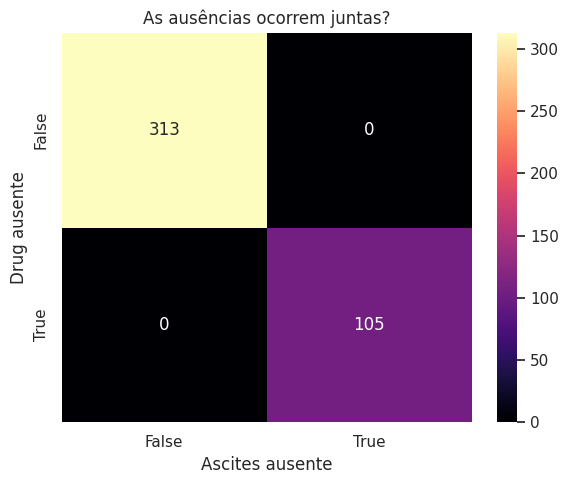

In [6]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())

tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

Prompt: Como seria a melhor de visualizar / checar se várois valores faltantes do dataset tem algum tipo de relação?(ex: tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show())

Resposta:

1. Matriz de correlação das ausências — minha primeira escolha
Essa é a análise que eu faria primeiro, porque compara todas as colunas de uma só vez. A ideia é transformar cada coluna em um indicador binário: True quando o valor está ausente e False quando está presente. Depois, calcular a correlação entre esses indicadores.

scikit-na documentation
+1


python
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Selecionar colunas que possuem valores ausentes
cols_com_ausentes = df.columns[df.isna().any()].tolist()

# Matriz binária: True = ausente; False = presente
ausencias = df[cols_com_ausentes].isna().astype(int)

# Correlação entre os padrões de ausência
corr_ausencias = ausencias.corr()

# Visualização
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_ausencias,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlação entre valores ausentes")
plt.tight_layout()
plt.show()

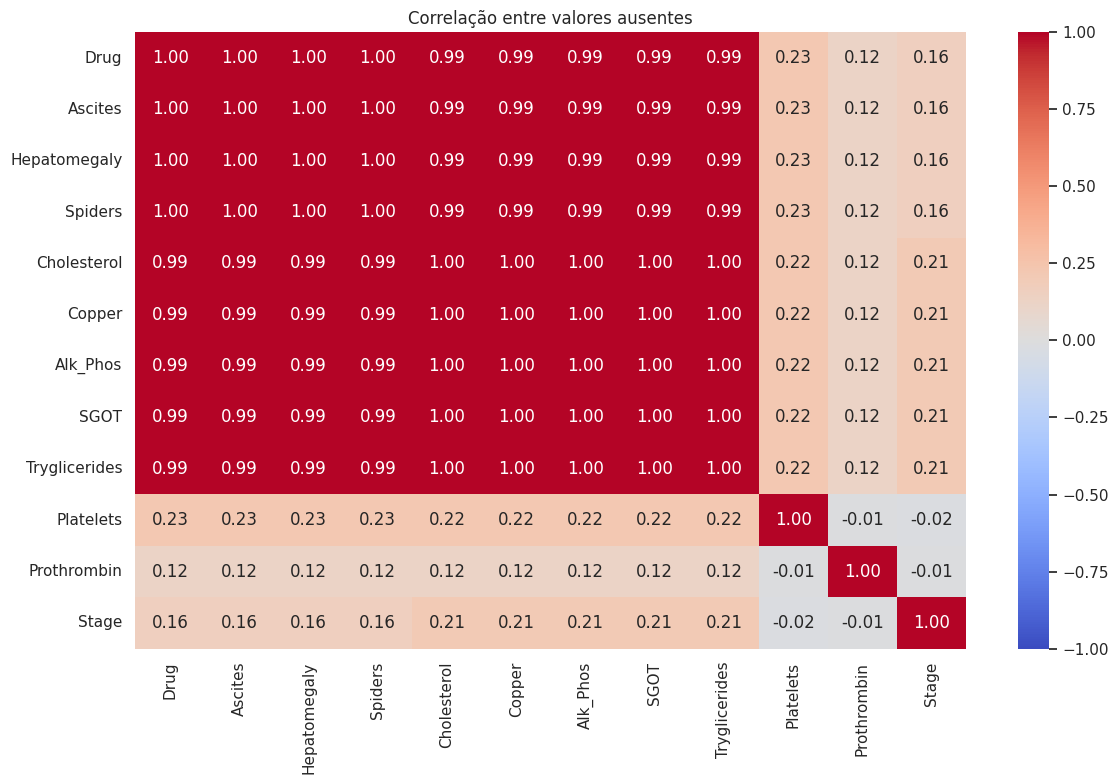

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Selecionar colunas que possuem valores ausentes
cols_com_ausentes = df.columns[df.isna().any()].tolist()

# Matriz binária: True = ausente; False = presente
ausencias = df[cols_com_ausentes].isna().astype(int)

# Correlação entre os padrões de ausência
corr_ausencias = ausencias.corr()

# Visualização
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_ausencias,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlação entre valores ausentes")
plt.tight_layout()
plt.show()



In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


# Algo de errado não está certo com as ausências. Lembrar de classificar entre
# MCAR: Mecanismo Aleatório e sem viés
# MAR: Mecanismo Randômico e com viés possível de corrigir
# MNAR: Mecanismo Não Randômico relacionada a própria feature --> Muito provavelmente é esse

print("Tamanho do dataset antes de tirar valores faltantes: ")
print(df_clean.shape)
df_clean = df_clean.dropna()
print("Tamanho do dataset depois de tirar valores faltantes: ")
print(df_clean.shape)

Tamanho do dataset antes de tirar valores faltantes: 
(418, 18)
Tamanho do dataset depois de tirar valores faltantes: 
(312, 18)


In [9]:

# Tipo Droga         105
# Idade                0
# Sexo                 0
# Ascites            105
# Hepatomegalia      105
# Spiders(Efeito)    105
# Edema                0
# Bilirubin            0
# Cholesterol        106
# Albumin              0
# Copper             106
# Alk_Phos           106
# SGOT               106
# triglicerídeos     106
# Plaquetas            7
# Protrombina          2
# Estágio              6

VARS_QUANT = ["Idade", "Bilirubin", "Albumin", "Copper", "Alk_Phos", "SGOT", "triglicerídeos", "Plaquetas", "Protrombina"]
VARS_QUALI = ["Sexo", "Ascites", "Hepatomegalia", "Spiders(Efeito)", "Edema", "Tipo Droga", "Estágio", "Status"]
df_clean[VARS_QUANT] = df_clean[VARS_QUANT].replace(
    r"^\s*NaNN\s*$", float("nan"), regex=True
)

df_clean[VARS_QUANT] = df_clean[VARS_QUANT].apply(
    pd.to_numeric, errors="coerce"
)
desc = df_clean[VARS_QUANT].describe().T
desc["skewness"] = df_clean[VARS_QUANT].skew()
desc["kurtosis"] = df_clean[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)



,mean,median,std,min,max,skewness,kurtosis
Idade,50.02,49.80,10.58,26.28,78.44,0.17,-0.53
Bilirubin,3.26,1.35,4.53,0.30,28.00,2.85,8.89
Albumin,3.52,3.55,0.42,1.96,4.64,-0.58,0.95
Copper,97.65,73.00,85.61,4.00,588.00,2.30,7.62
Alk_Phos,1982.66,1259.00,2140.39,289.00,13862.40,2.99,9.66
SGOT,122.56,114.70,56.70,26.35,457.25,1.45,4.31
triglicerídeos,124.70,108.00,65.15,33.00,598.00,2.52,11.80
Plaquetas,261.94,257.00,95.61,62.00,563.00,0.38,-0.00
Protrombina,10.73,10.60,1.00,9.00,17.10,1.73,6.02


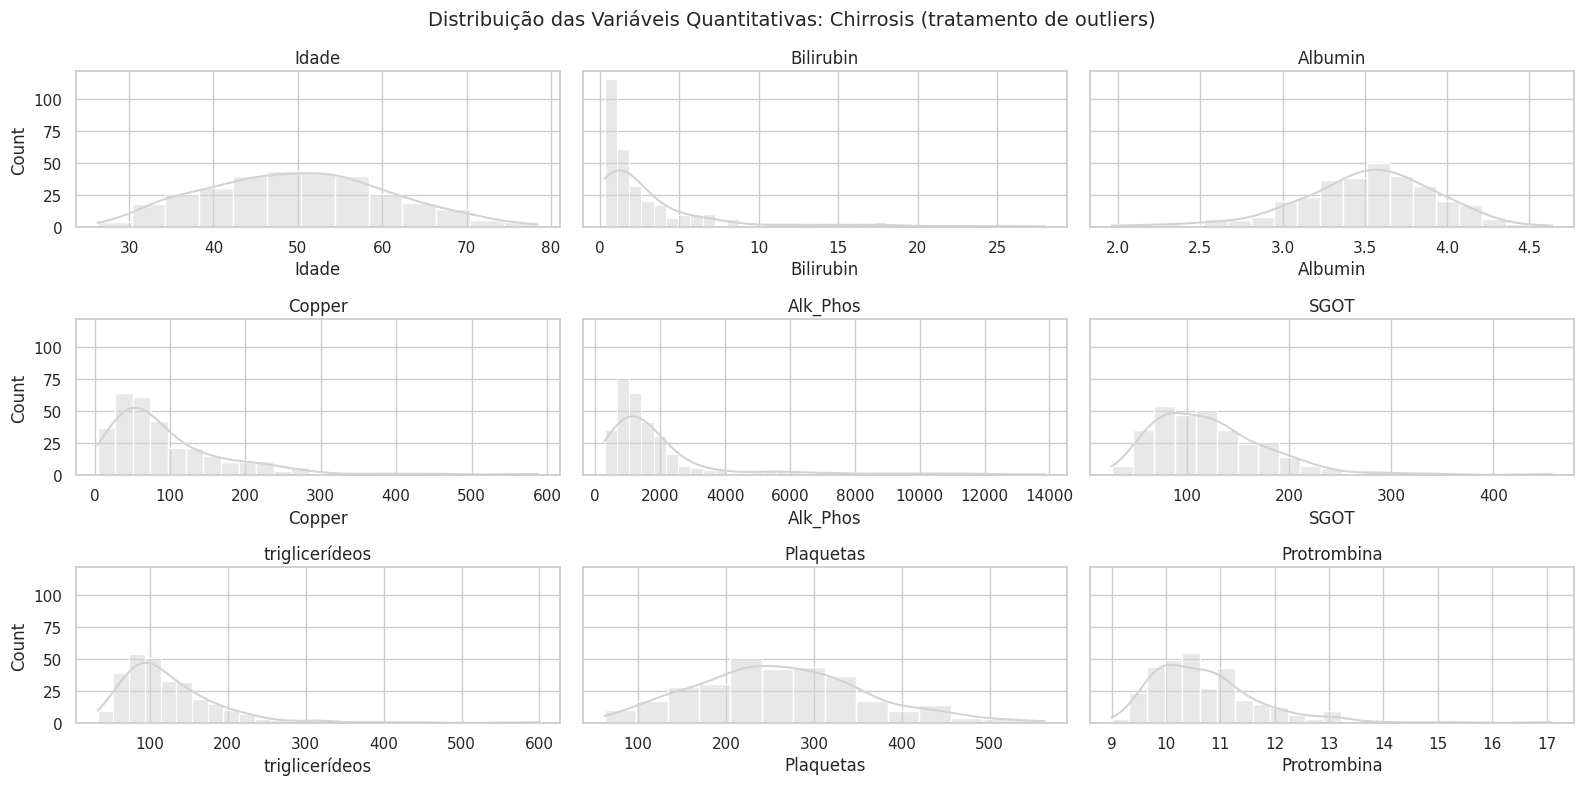

In [10]:

fig, axes = plt.subplots(3, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df_clean, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Chirrosis (tratamento de outliers)", fontsize=14)
plt.tight_layout()
plt.show()

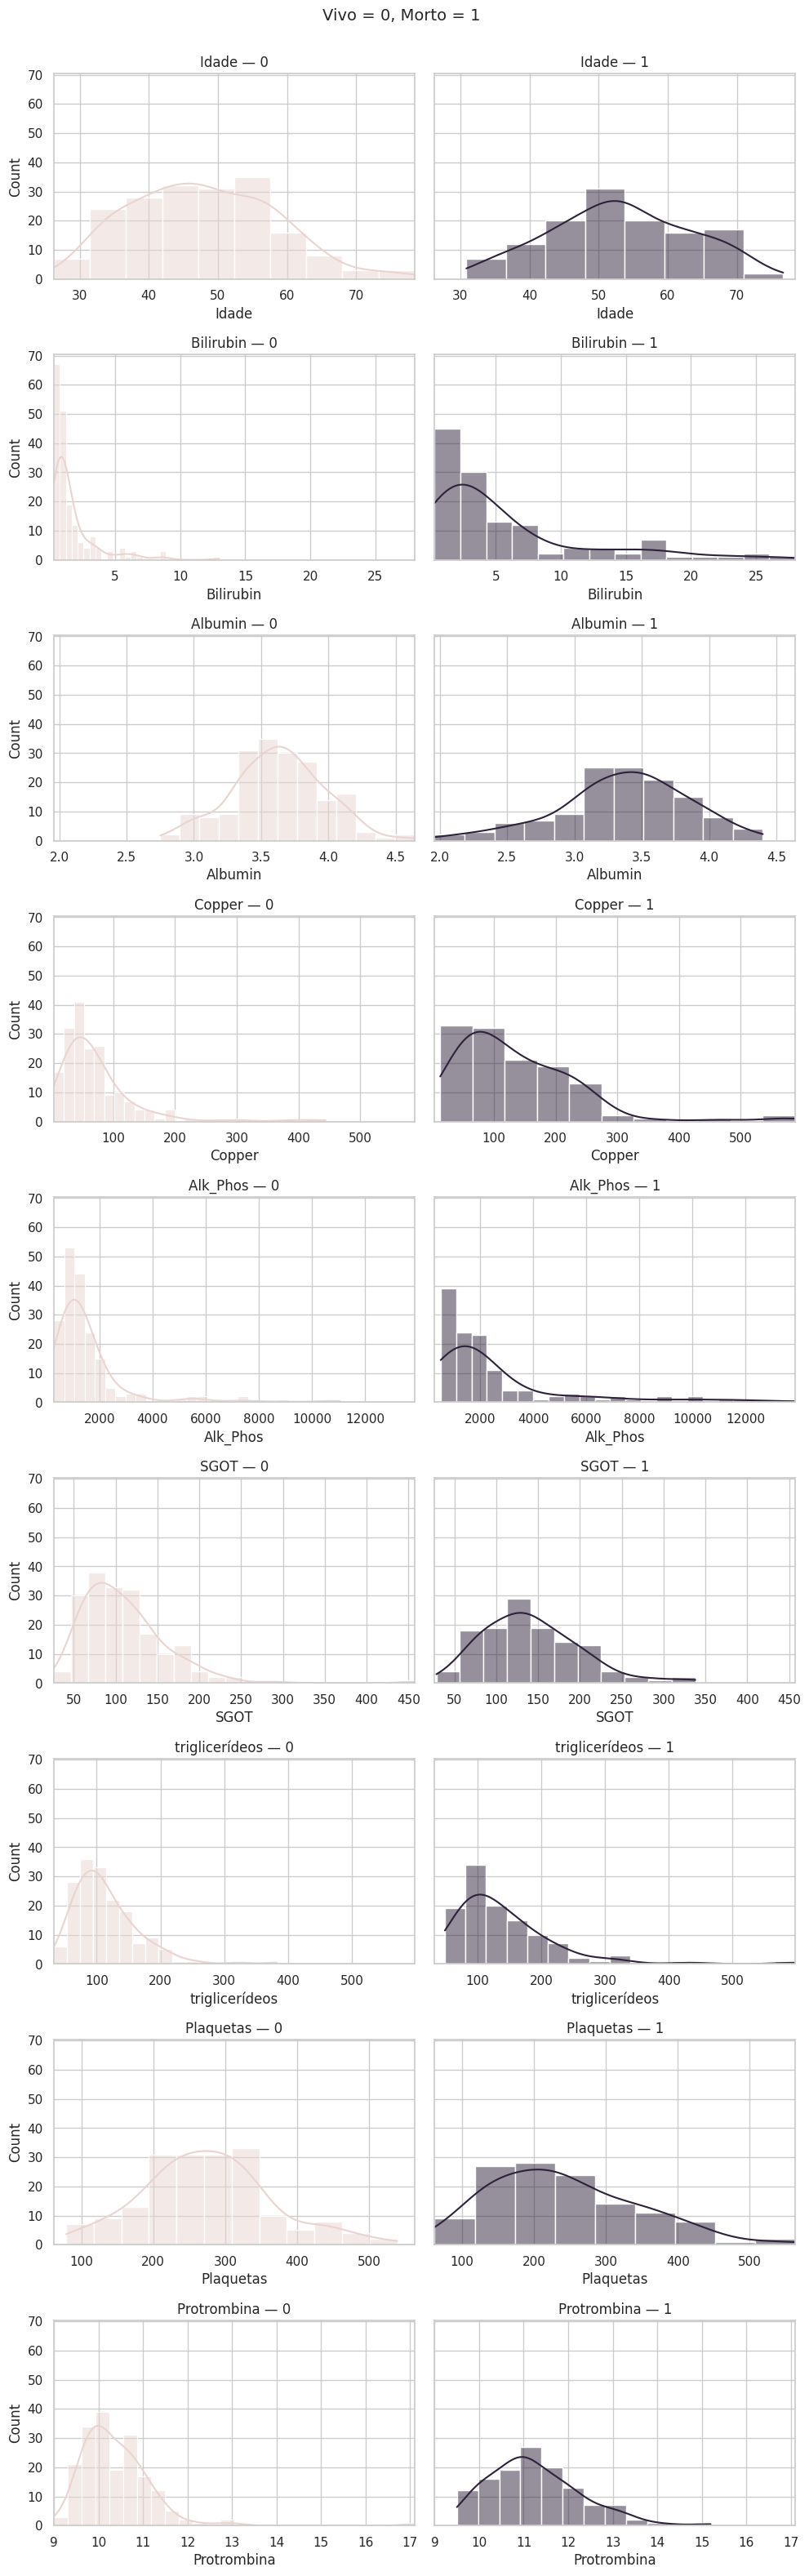

In [11]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df_clean[col].min(), df_clean[col].max())
    for j, (classe, cor) in enumerate([("0", COR_CONTEXTO), ("1", COR_DESTAQUE)]):
        subset = df_clean[df_clean["Status"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")


fig.suptitle("Vivo = 0, Morto = 1", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

A vizualização distribuição acima foi descartada pois não apresenta uma explicação visual das diferenças entre as classes que sobreviveram e morreram. Em vez disso, a visualização para distribuição escolhida foi o gráfico de proporção acumulada


Shapiro-Wilk — Idade:
Estatística = 0.9900, p-valor = 0.03217
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


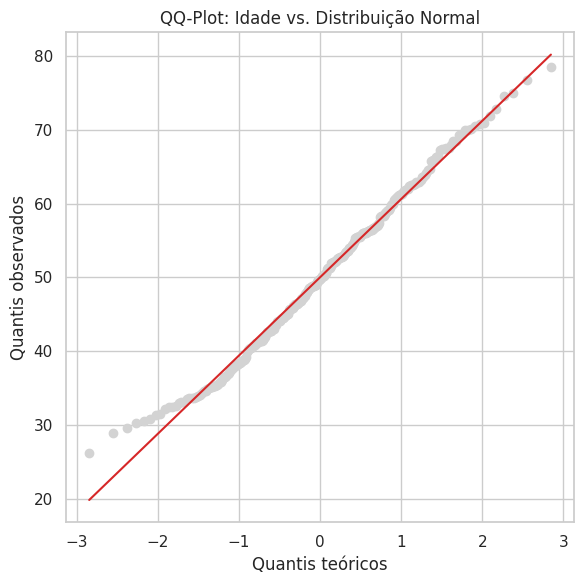


Shapiro-Wilk — Bilirubin:
Estatística = 0.6214, p-valor = 1.156e-25
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


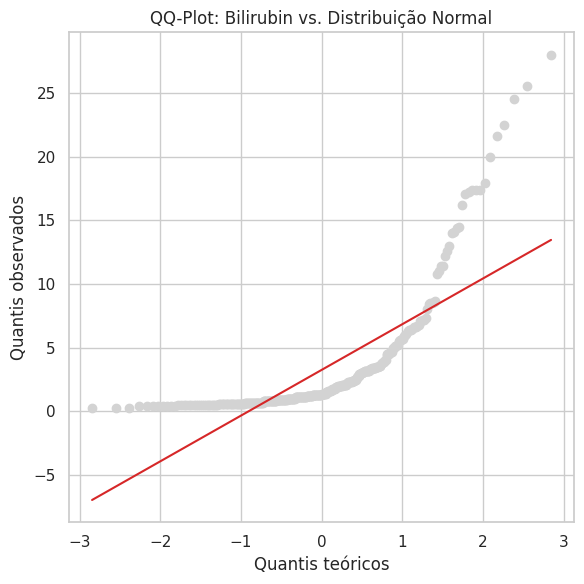


Shapiro-Wilk — Albumin:
Estatística = 0.9799, p-valor = 0.0002296
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


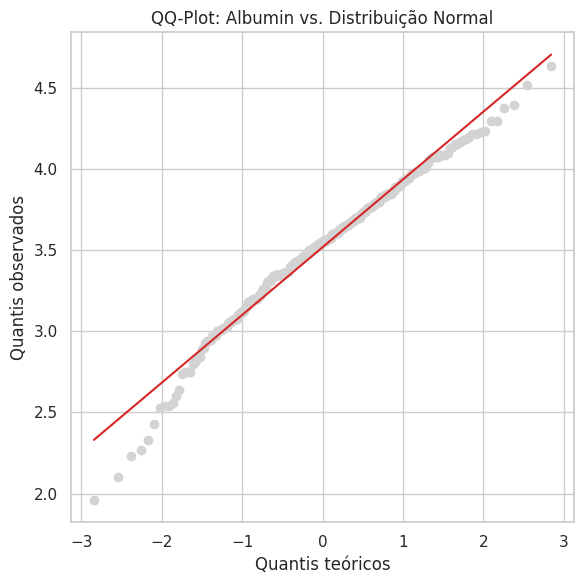


Shapiro-Wilk — Copper:
Estatística = 0.7874, p-valor = 8.351e-20
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


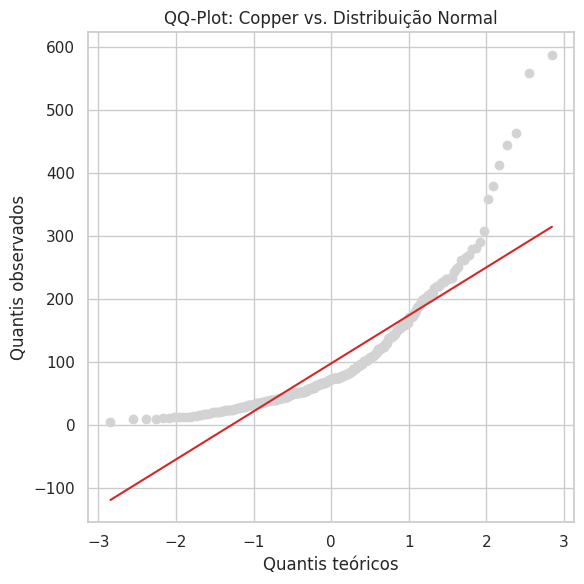


Shapiro-Wilk — Alk_Phos:
Estatística = 0.6133, p-valor = 6.85e-26
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


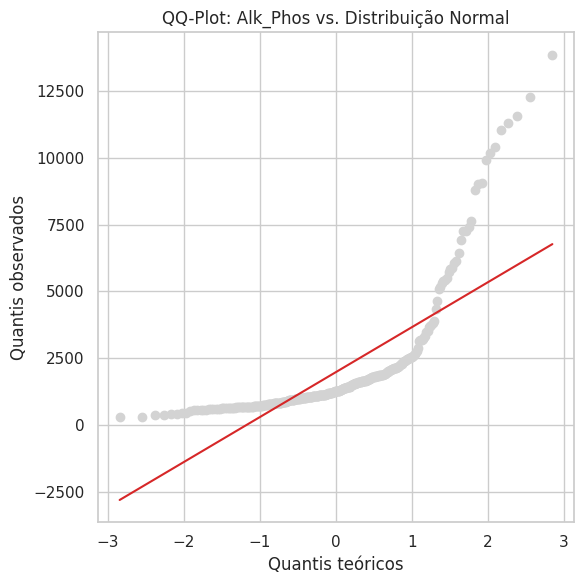


Shapiro-Wilk — SGOT:
Estatística = 0.9118, p-valor = 1.467e-12
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


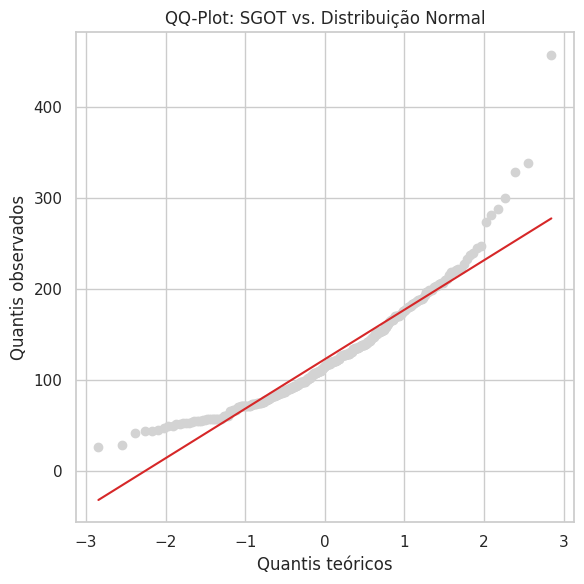


Shapiro-Wilk — triglicerídeos:
Estatística = 0.8150, p-valor = 1.221e-17
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


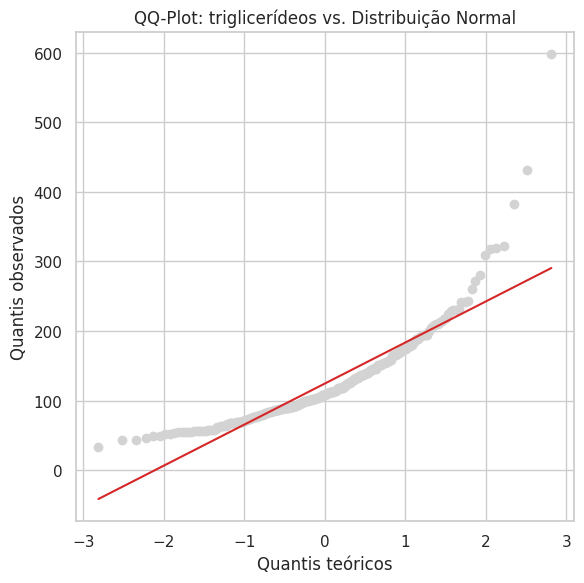


Shapiro-Wilk — Plaquetas:
Estatística = 0.9880, p-valor = 0.01169
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


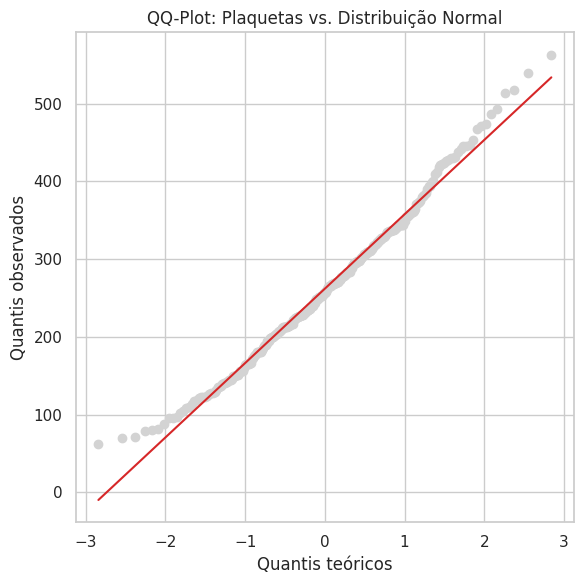


Shapiro-Wilk — Protrombina:
Estatística = 0.8851, p-valor = 1.457e-14
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


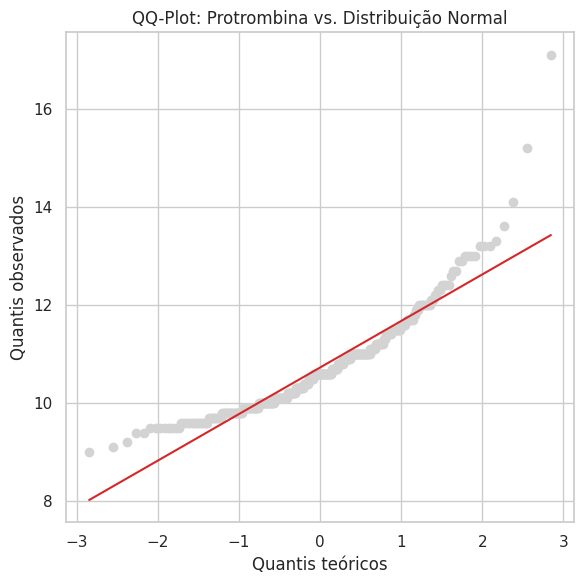

In [12]:
resultados_shapiro = []

for variavel in VARS_QUANT:

    # Remover valores ausentes
    dados = df_clean[variavel].dropna()

    # Evitar erros em variáveis com poucas observações ou valores constantes
    if len(dados) < 3 or dados.nunique() < 2:
        print(f"{variavel}: dados insuficientes ou constantes. Teste não realizado.")
        continue

    # Teste de Shapiro-Wilk
    stat_sw, p_valor_sw = stats.shapiro(dados)

    print(f"\nShapiro-Wilk — {variavel}:")
    print(f"Estatística = {stat_sw:.4f}, p-valor = {p_valor_sw:.4g}")
    print(
        "Rejeita H0 (normalidade)?",
        "Sim" if p_valor_sw < 0.05 else "Não",
        "(alpha = 0.05)"
    )

    # Guardar resultados para análise posterior
    resultados_shapiro.append({
        "Variável": variavel,
        "Estatística": stat_sw,
        "p-valor": p_valor_sw,
        "Rejeita H0": p_valor_sw < 0.05
    })

    # QQ-Plot
    fig, ax = plt.subplots(figsize=(6, 6))

    stats.probplot(dados, dist="norm", plot=ax)

    # Manter o padrão visual original
    ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
    ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
    ax.get_lines()[1].set_color(COR_ALERTA)

    ax.set_title(f"QQ-Plot: {variavel} vs. Distribuição Normal")
    ax.set_xlabel("Quantis teóricos")
    ax.set_ylabel("Quantis observados")

    plt.tight_layout()
    plt.show()

# Consolidar os resultados em um DataFrame
df_shapiro = pd.DataFrame(resultados_shapiro)

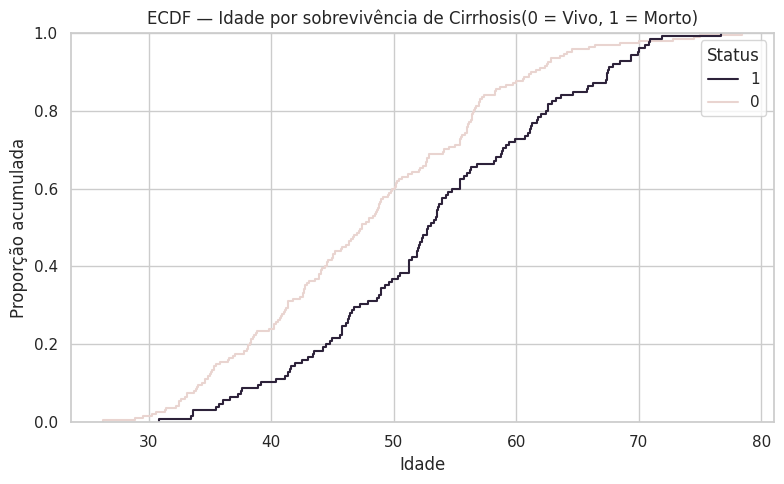

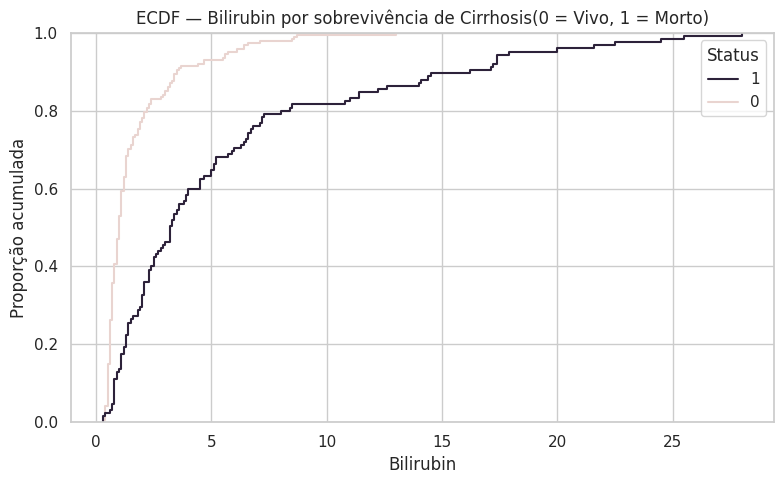

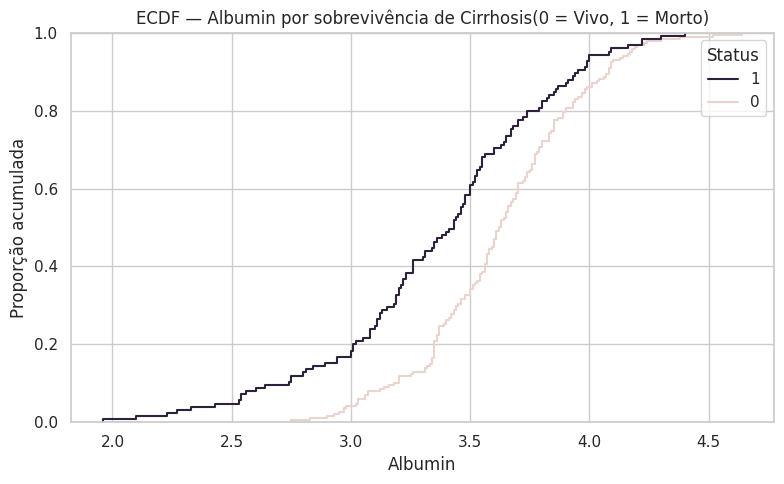

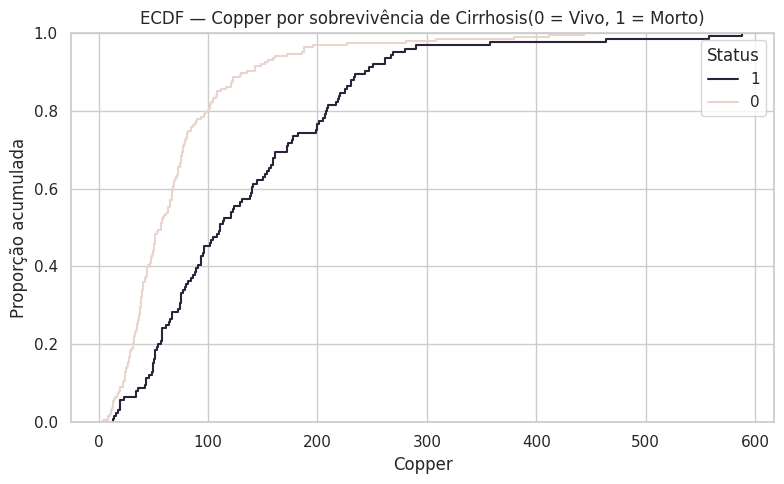

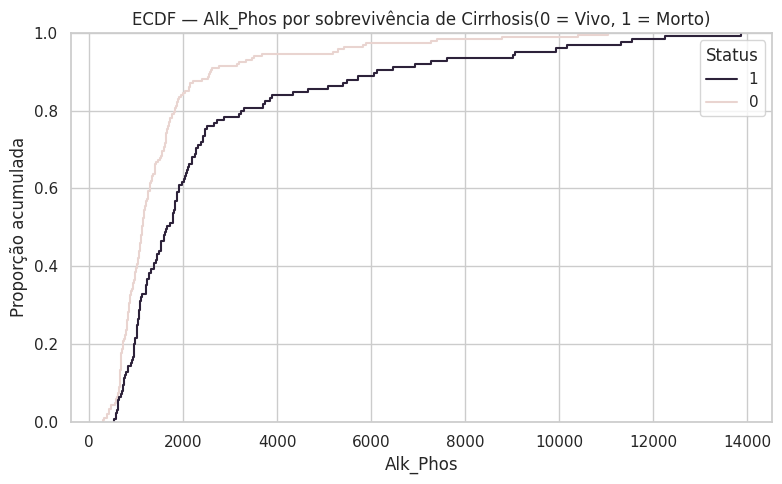

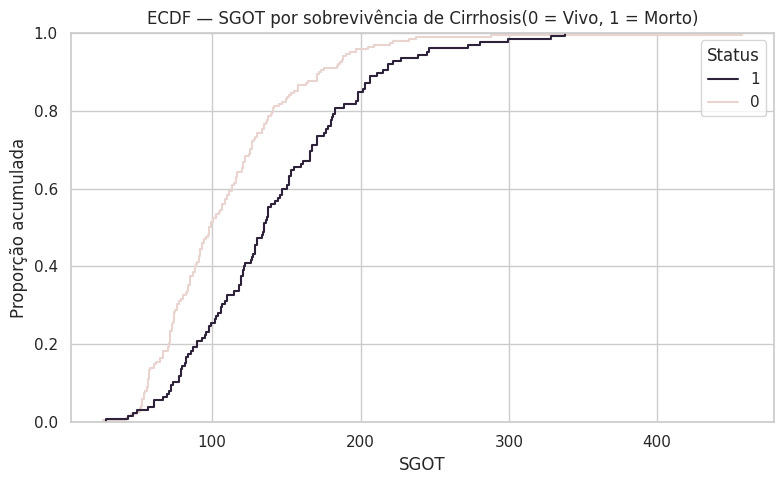

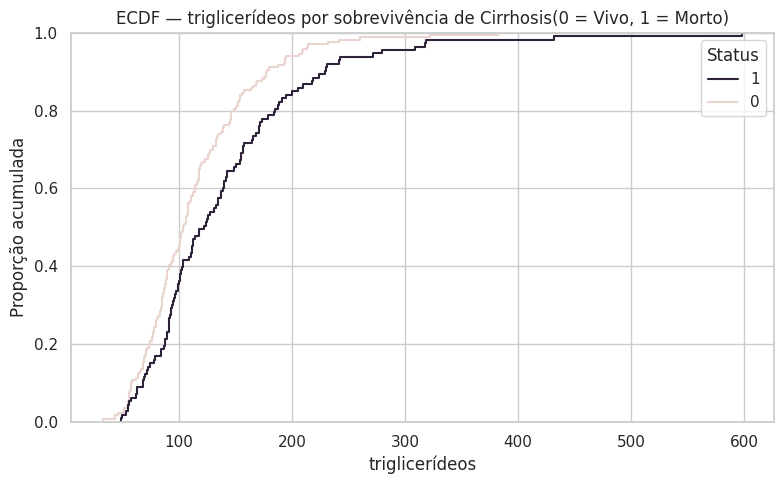

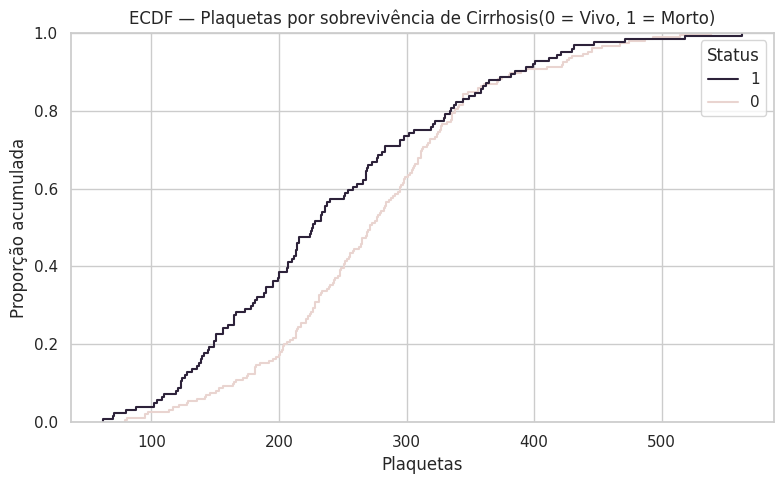

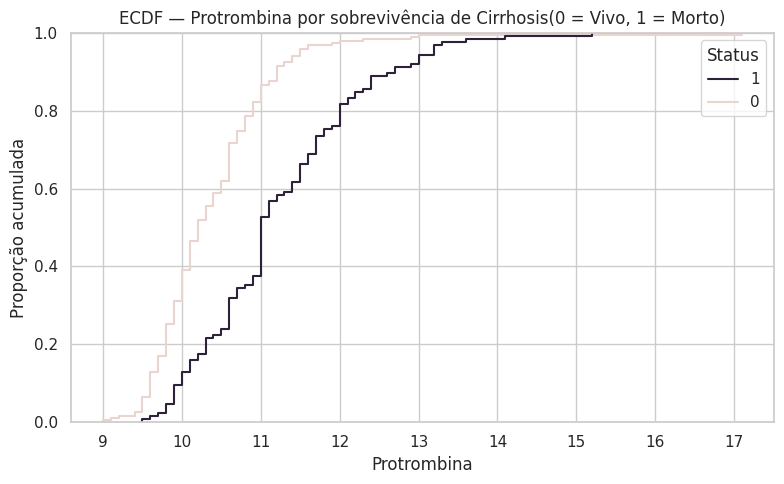

In [13]:
for variavel in VARS_QUANT:

    plt.figure(figsize=(8, 5))

    sns.ecdfplot(
        data=df_clean,
        x=variavel,
        hue="Status",
        palette={
            "0": COR_CONTEXTO,
            "1": COR_DESTAQUE
        }
    )

    plt.title(f"ECDF — {variavel} por sobrevivência de Cirrhosis(0 = Vivo, 1 = Morto)")
    plt.xlabel(variavel)
    plt.ylabel("Proporção acumulada")

    plt.tight_layout()
    plt.show()

    # Albumina parece ser um fator decisivo, com a distribuição pupulacional das pessoas que morreram terem sua taxa de distribuição iniciarem com seus valores
    # muito inferiores em relação as pessoas que sobreviveram

In [14]:
print(df_clean.loc[df_clean['Status'] == '0', "Bilirubin"].max())
print(df_clean.loc[df_clean['Status'] == '1', "Bilirubin"].max())

# Bilirubin Acima de um certo ponto parecem resultar em fatalidades garantidas

13.0
28.0


In [15]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df_clean[col])
    n_outliers = ((df_clean[col] < lim_inf) | (df_clean[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
Idade,20.53,78.43,1.0
Bilirubin,-3.14,7.36,30.0
Albumin,2.58,4.53,11.0
Copper,-81.38,245.62,17.0
Alk_Phos,-791.25,3642.75,35.0
SGOT,-26.35,258.85,7.0
triglicerídeos,-15.88,251.12,10.0
Plaquetas,15.62,506.62,4.0
Protrombina,8.35,12.75,14.0


Prompt:Porque o seguinte gráfico não está mostrando as linhas corretamente: df_clean["Alk_Phos_log"] = np.log1p(df_clean["Alk_Phos"])
media_alkl = df_clean["Alk_Phos_log"].mean()
mediana_alkl = df_clean["Alk_Phos_log"].median()
media_alk = df_clean["Alk_Phos"].mean()
mediana_alk = df_clean["Alk_Phos"].median()


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df_clean, x="Alk_Phos", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Alk_Phos original (skew={df_clean['Alk_Phos'].skew():.2f})")
plt.axvline(media_alk, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_alk:.1f}")
plt.axvline(mediana_alk, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_alk:.1f}")
sns.histplot(data=df_clean, x="Alk_Phos_log", kde=True, color=COR_NEUTRA, ax=axes[1])
plt.axvline(media_alkl, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_alkl:.1f}")
plt.axvline(mediana_alkl, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_alkl:.1f}")
axes[1].set_title(f"log(1 + Alk_Phos) (skew={df_clean['Alk_Phos_log'].skew():.2f})")



plt.tight_layout()
plt.show()

resposta: O problema está no uso de plt.axvline() em vez de axes[0].axvline() e axes[1].axvline().

Quando você usa plt.axvline(), o Matplotlib desenha a linha no eixo atualmente ativo, que pode não ser aquele em que você deseja exibi-la. Além disso, as médias e medianas precisam corresponder à escala de cada gráfico: as da variável original no primeiro e as da variável transformada com log no segundo.

Código corrigido

python

df_clean["Alk_Phos_log"] = np.log1p(df_clean["Alk_Phos"])

media_alk = df_clean["Alk_Phos"].mean()
mediana_alk = df_clean["Alk_Phos"].median()

media_alkl = df_clean["Alk_Phos_log"].mean()
mediana_alkl = df_clean["Alk_Phos_log"].median()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico original
sns.histplot(
    data=df_clean, x="Alk_Phos", kde=True,
    color=COR_NEUTRA, ax=axes[0]
)

axes[0].axvline(
    media_alk, color=COR_ALERTA, linestyle="--",
    linewidth=2, label=f"Média = {media_alk:.1f}"
)
axes[0].axvline(
    mediana_alk, color="black", linestyle="-",
    linewidth=2, label=f"Mediana = {mediana_alk:.1f}"
)

axes[0].set_title(
    f"Alk_Phos original (skew={df_clean['Alk_Phos'].skew():.2f})"
)
axes[0].legend()

# Gráfico transformado
sns.histplot(
    data=df_clean, x="Alk_Phos_log", kde=True,
    color=COR_NEUTRA, ax=axes[1]
)

axes[1].axvline(
    media_alkl, color=COR_ALERTA, linestyle="--",
    linewidth=2, label=f"Média = {media_alkl:.2f}"
)
axes[1].axvline(
    mediana_alkl, color="black", linestyle="-",
    linewidth=2, label=f"Mediana = {mediana_alkl:.2f}"
)

axes[1].set_title(
    f"log(1 + Alk_Phos) (skew={df_clean['Alk_Phos_log'].skew():.2f})"
)
axes[1].legend()

plt.tight_layout()
plt.show()

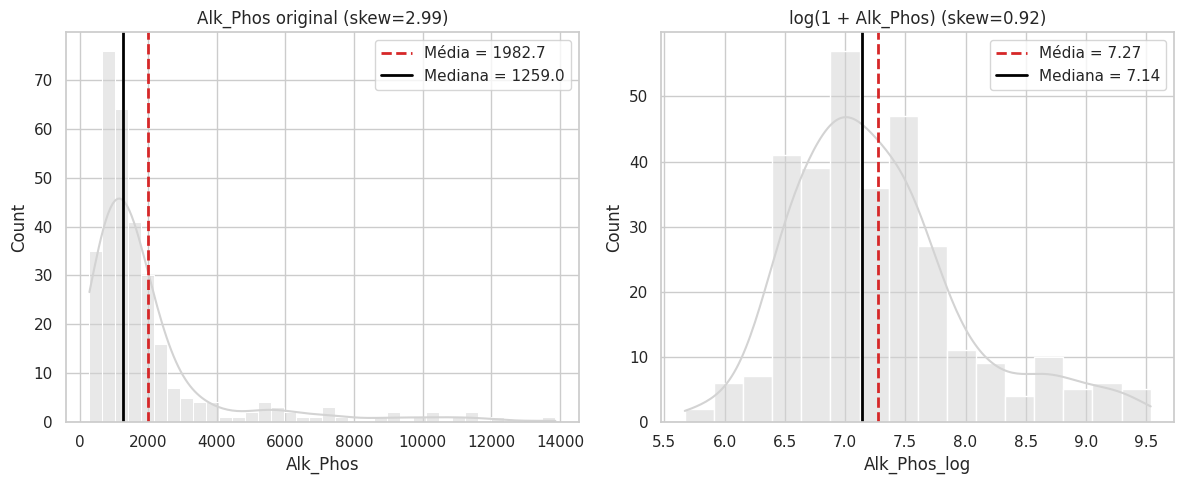

In [16]:

df_clean["Alk_Phos_log"] = np.log1p(df_clean["Alk_Phos"])

media_alk = df_clean["Alk_Phos"].mean()
mediana_alk = df_clean["Alk_Phos"].median()

media_alkl = df_clean["Alk_Phos_log"].mean()
mediana_alkl = df_clean["Alk_Phos_log"].median()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico original
sns.histplot(data=df_clean, x="Alk_Phos", kde=True,color=COR_NEUTRA, ax=axes[0])

axes[0].axvline(media_alk, color=COR_ALERTA, linestyle="--",linewidth=2, label=f"Média = {media_alk:.1f}")
axes[0].axvline(mediana_alk, color="black", linestyle="-",linewidth=2, label=f"Mediana = {mediana_alk:.1f}")
axes[0].set_title(f"Alk_Phos original (skew={df_clean['Alk_Phos'].skew():.2f})")
axes[0].legend()

# Gráfico transformado
sns.histplot(data=df_clean, x="Alk_Phos_log", kde=True,color=COR_NEUTRA, ax=axes[1])
axes[1].axvline(media_alkl, color=COR_ALERTA, linestyle="--",linewidth=2, label=f"Média = {media_alkl:.2f}")
axes[1].axvline(mediana_alkl, color="black", linestyle="-",linewidth=2, label=f"Mediana = {mediana_alkl:.2f}")
axes[1].set_title(f"log(1 + Alk_Phos) (skew={df_clean['Alk_Phos_log'].skew():.2f})")
axes[1].legend()
plt.tight_layout()
plt.show()

df_clean.drop(columns=["Alk_Phos_log"], inplace=True)


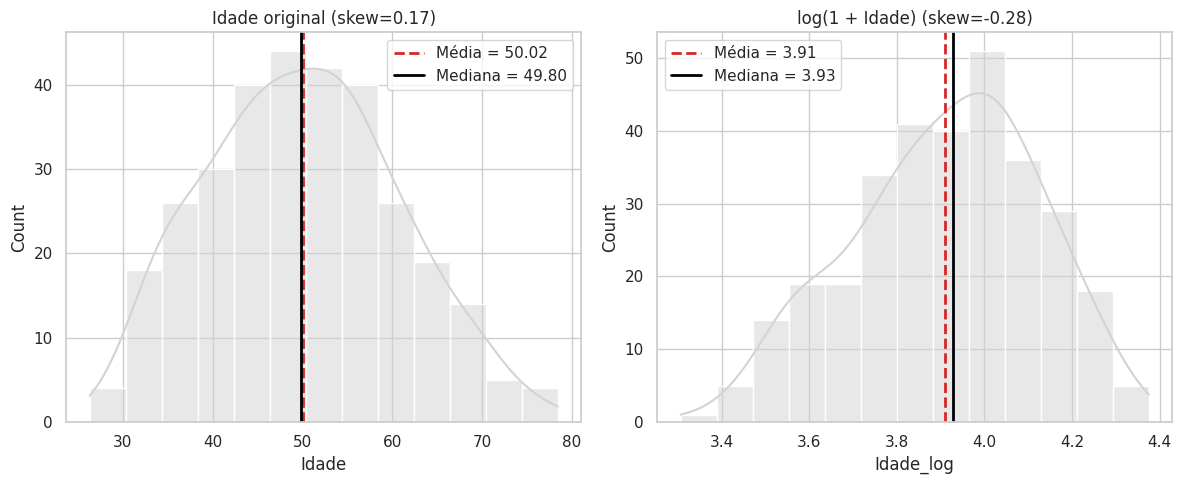

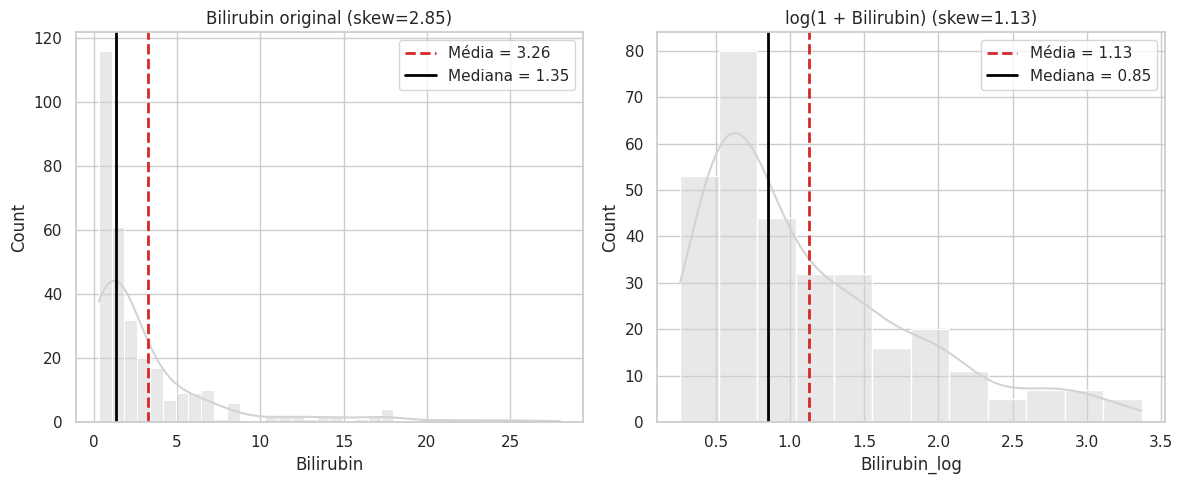

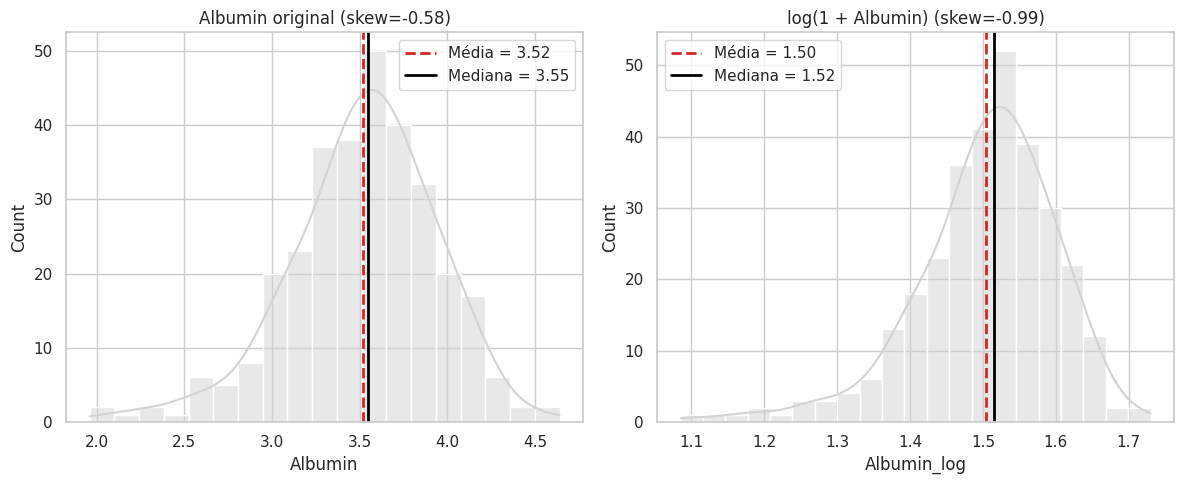

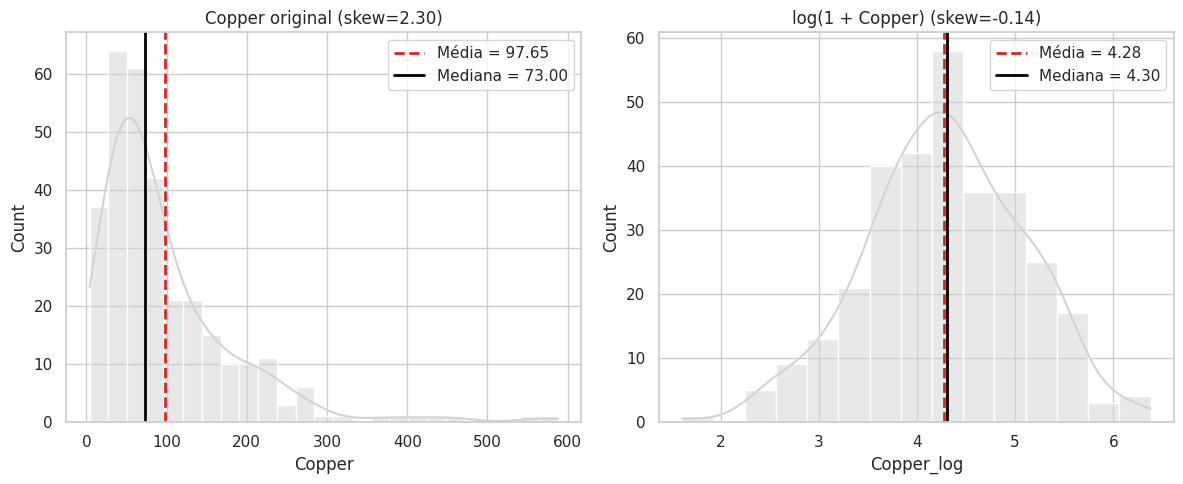

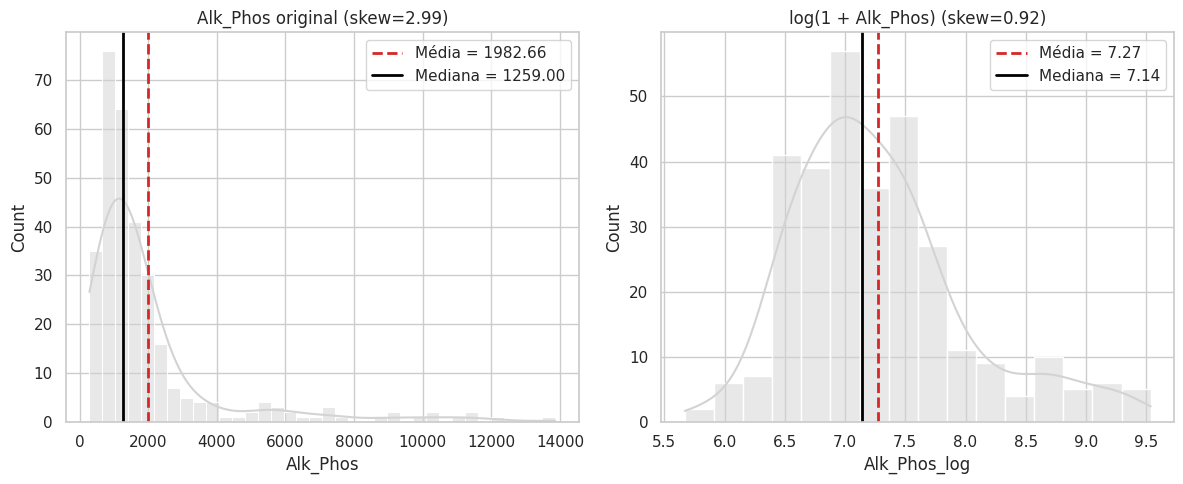

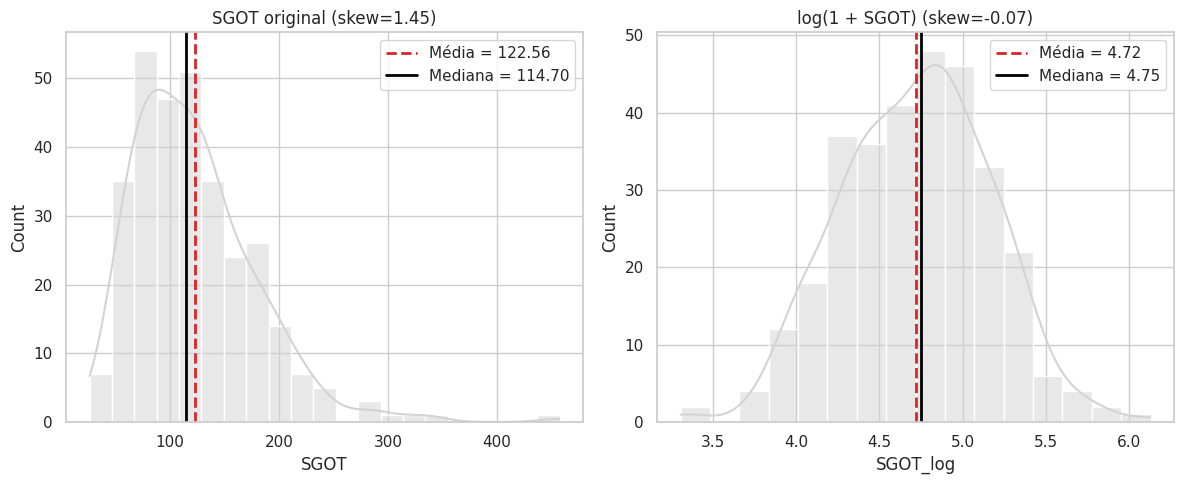

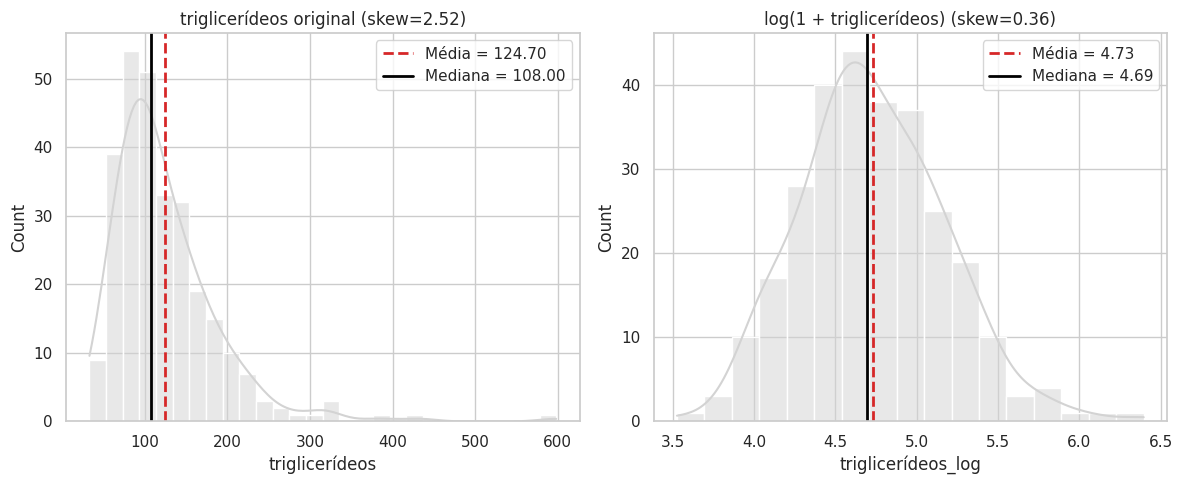

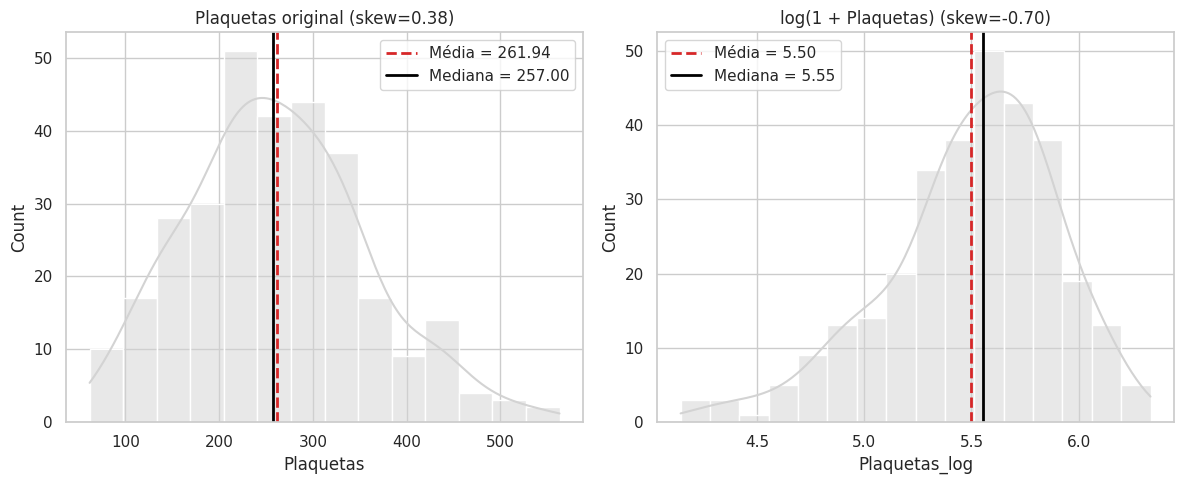

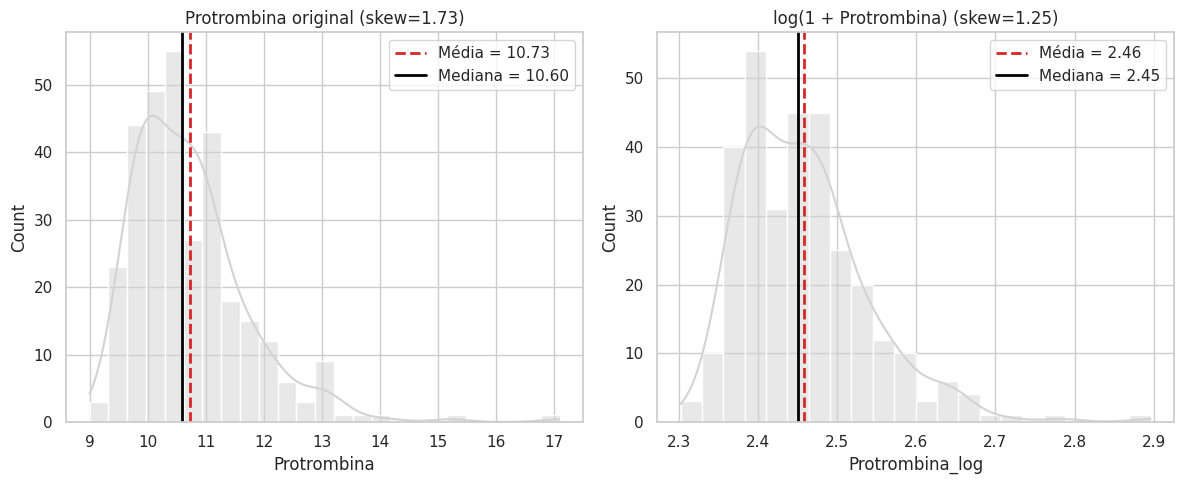

In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Criar um DataFrame separado com as variáveis transformadas
df_log = pd.DataFrame(index=df_clean.index)

for variavel in VARS_QUANT:

    # Transformar a variável e armazenar no DataFrame separado
    coluna_log = f"{variavel}_log"
    df_log[coluna_log] = np.log1p(df_clean[variavel])

    # Estatísticas da variável original
    media = df_clean[variavel].mean()
    mediana = df_clean[variavel].median()
    skew_original = df_clean[variavel].skew()

    # Estatísticas da variável transformada
    media_log = df_log[coluna_log].mean()
    mediana_log = df_log[coluna_log].median()
    skew_log = df_log[coluna_log].skew()

    # Criar os gráficos
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Variável original
    sns.histplot(
        data=df_clean, x=variavel,
        kde=True, color=COR_NEUTRA, ax=axes[0]
    )

    axes[0].axvline(
        media, color=COR_ALERTA, linestyle="--",
        linewidth=2, label=f"Média = {media:.2f}"
    )
    axes[0].axvline(
        mediana, color="black", linestyle="-",
        linewidth=2, label=f"Mediana = {mediana:.2f}"
    )

    axes[0].set_title(
        f"{variavel} original (skew={skew_original:.2f})"
    )
    axes[0].legend()

    # Variável transformada
    sns.histplot(
        data=df_log, x=coluna_log,
        kde=True, color=COR_NEUTRA, ax=axes[1]
    )

    axes[1].axvline(
        media_log, color=COR_ALERTA, linestyle="--",
        linewidth=2, label=f"Média = {media_log:.2f}"
    )
    axes[1].axvline(
        mediana_log, color="black", linestyle="-",
        linewidth=2, label=f"Mediana = {mediana_log:.2f}"
    )

    axes[1].set_title(
        f"log(1 + {variavel}) (skew={skew_log:.2f})"
    )
    axes[1].legend()

    plt.tight_layout()
    plt.show()


In [18]:
# Variáveis mais afetadas pela transformação e que serão transformadas: triglicerídeos, Alk_Phos_log, Copper, Bilirubin

In [19]:
for col in VARS_QUALI:
    freq_abs = df_clean[col].value_counts()
    freq_rel = df_clean[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- Sexo ---
           absoluta  relativa
Sexo                         
Feminino        276     0.885
Masculino        36     0.115
\n--- Ascites ---
         absoluta  relativa
Ascites                    
0             288     0.923
1              24     0.077
\n--- Hepatomegalia ---
               absoluta  relativa
Hepatomegalia                    
1                   160     0.513
0                   152     0.487
\n--- Spiders(Efeito) ---
                 absoluta  relativa
Spiders(Efeito)                    
0                     222     0.712
1                      90     0.288
\n--- Edema ---
       absoluta  relativa
Edema                    
N           263     0.843
S            29     0.093
Y            20     0.064
\n--- Tipo Droga ---
                 absoluta  relativa
Tipo Droga                         
D-penicillamine       158     0.506
Placebo               154     0.494
\n--- Estágio ---
         absoluta  relativa
Estágio                    
3.0           120   

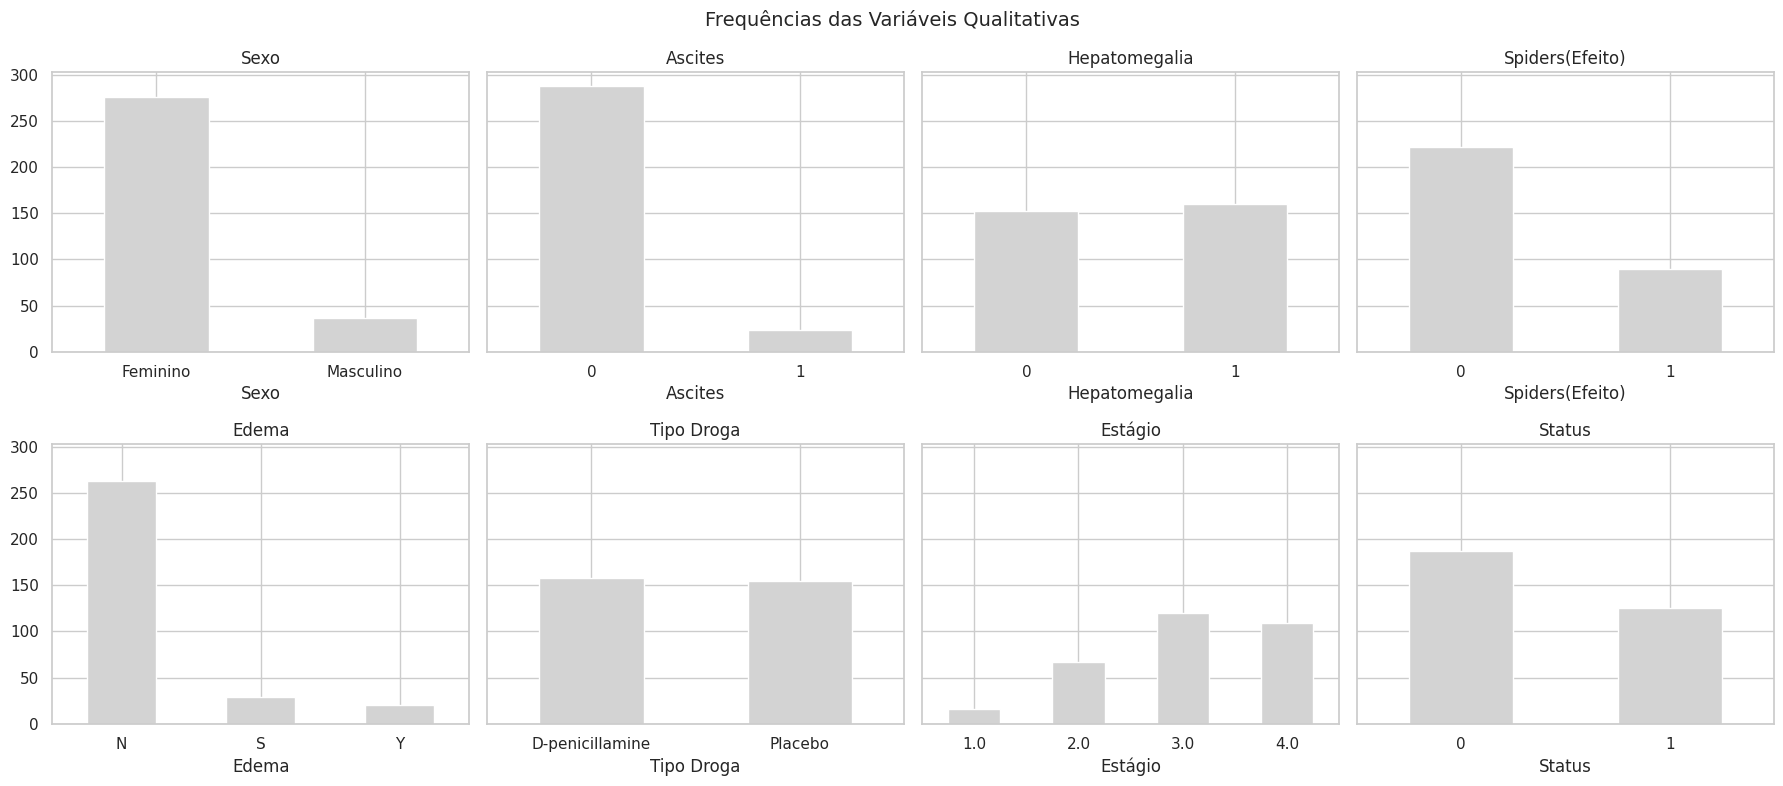

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df_clean[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

In [23]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })
vars_para_checar = VARS_QUALI + ["Status"]
pd.DataFrame({col: metrica_desbalanceamento(df_clean[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
Sexo,2.0,7.67,0.516
Ascites,2.0,12.00,0.391
Hepatomegalia,2.0,1.05,1.000
Spiders(Efeito),2.0,2.47,0.867
Edema,3.0,13.15,0.492
Tipo Droga,2.0,1.03,1.000
Estágio,4.0,7.50,0.878
Status,2.0,1.50,0.971


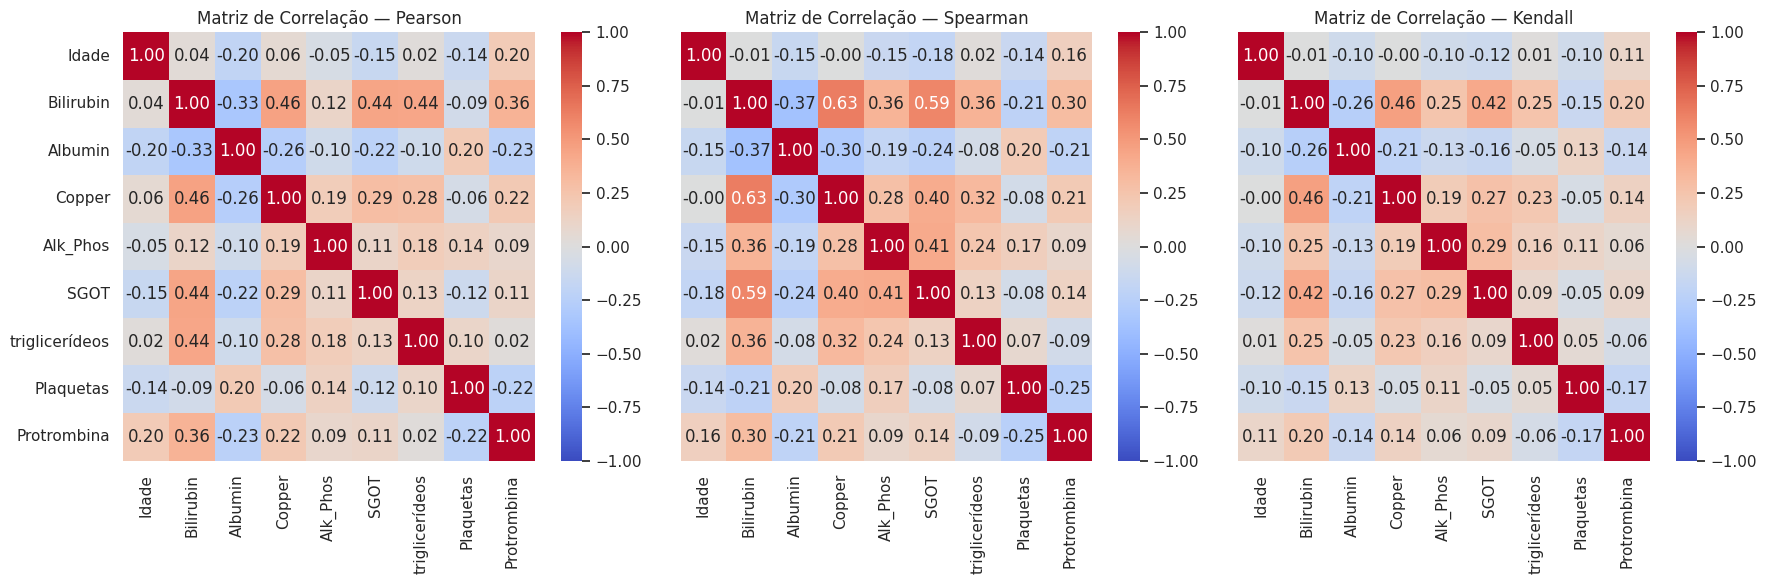

In [27]:
corr_pearson = df_clean[VARS_QUANT].corr(method="pearson")
corr_spearman = df_clean[VARS_QUANT].corr(method="spearman")
corr_kendall = df_clean[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(18, 6),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()

In [31]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)
# 🆕 NOVA CÉLULA — dataset ORIGINAL (reconstruído a partir do objeto `heart`, que não foi alterado)
df_raw = pd.concat([cirrhosis_patient_survival_prediction.data.features, cirrhosis_patient_survival_prediction.data.targets], axis=1)
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")

Raw salvo em data/raw/dataset.csv — 418 linhas x 19 colunas
Clean salvo em data/clean/dataset.csv — 418 linhas x 18 colunas
Linhas removidas no tratamento: 0
